In [1]:
import os, glob, json, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
from scipy import ndimage as ndi
from tqdm.auto import tqdm
import torch
from torch.utils.data import Dataset, DataLoader
import kagglehub

SEED = 42
N_TRAIN = None
N_TEST = None
VAL_FRACTION = 0.1    # 10% of the training samples used for validation
H, W = 256, 192                      # working resolution (512, then 384)
ORIGINAL_H, ORIGINAL_W = 1024, 768   # resolution
OUT = f"vitonhd_{H}x{W}"             # where cleaned data is saved

FOLDERS = ["image", "cloth", "cloth-mask", "agnostic-v3.2", "openpose_json", "image-densepose",
           "image-parse-v3", "image-parse-agnostic-v3.2"]

PARSE_FOLDERS = ["image-parse-v3", "image-parse-agnostic-v3.2"]

UPPER_JOINTS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 12, 15, 16, 17, 18]

rng = random.Random(SEED)

In [2]:
ROOT = kagglehub.dataset_download("marquis03/high-resolution-viton-zalando-dataset")
TRAIN_DIR = os.path.join(ROOT, "train")
TEST_DIR = os.path.join(ROOT, "test")

print("Dataset location:", ROOT)
print("Folders in train:", sorted(os.listdir(TRAIN_DIR)))

100%|██████████| 4.39G/4.39G [04:11<00:00, 18.7MB/s]

Extracting files...


Dataset location: /root/.cache/kagglehub/datasets/marquis03/high-resolution-viton-zalando-dataset/versions/1
Folders in train: ['agnostic-v3.2', 'cloth', 'cloth-mask', 'image', 'image-densepose', 'image-parse-agnostic-v3.2', 'image-parse-v3', 'openpose_img', 'openpose_json']


In [3]:
# Match the files across folders by sample ID
def index_split(split_dir):
    files = {}
    for folder in FOLDERS:
        paths = glob.glob(os.path.join(split_dir, folder, "*"))
        files[folder] = {os.path.basename(p).split(".")[0].replace("_keypoints", ""): p for p in paths}
        print(f"  {folder:<26} {len(paths):>6} files")

    complete = sorted(set.intersection(*(set(f) for f in files.values())))
    print(f"  complete samples: {len(complete)}\n")
    return complete, files

print("train"); train_ids, train_files = index_split(TRAIN_DIR)
print("test");  test_ids,  test_files  = index_split(TEST_DIR)

train
  image                       11647 files
  cloth                       11647 files
  cloth-mask                  11647 files
  agnostic-v3.2               11647 files
  openpose_json               11647 files
  image-densepose             11647 files
  image-parse-v3              11647 files
  image-parse-agnostic-v3.2   11647 files
  complete samples: 11647

test
  image                        2032 files
  cloth                        2032 files
  cloth-mask                   2032 files
  agnostic-v3.2                2032 files
  openpose_json                2032 files
  image-densepose              2032 files
  image-parse-v3               2032 files
  image-parse-agnostic-v3.2    2032 files
  complete samples: 2032



In [4]:
train_pool = rng.sample(train_ids, N_TRAIN or len(train_ids))   # random order
test_sub = rng.sample(test_ids, N_TEST or len(test_ids))

n_val = int(len(train_pool) * VAL_FRACTION)
val_sub, train_sub = train_pool[:n_val], train_pool[n_val:]
print(f"Working with {len(train_sub)} train, {len(val_sub)} validation and {len(test_sub)} test samples")

Working with 10483 train, 1164 validation and 2032 test samples


In [5]:
def load_pose(path): # OpenPose keypoints an array with one row per joint: (x, y, confidence)
    with open(path) as f:
        points = json.load(f)["people"][0]["pose_keypoints_2d"]
    return np.array(points, dtype=np.float32).reshape(-1, 3)

def load_mask(path, size=None):
    mask = Image.open(path).convert("L")
    if size:
        mask = mask.resize(size, Image.NEAREST)   # NEAREST keeps it purely black & white
    return np.array(mask) > 127

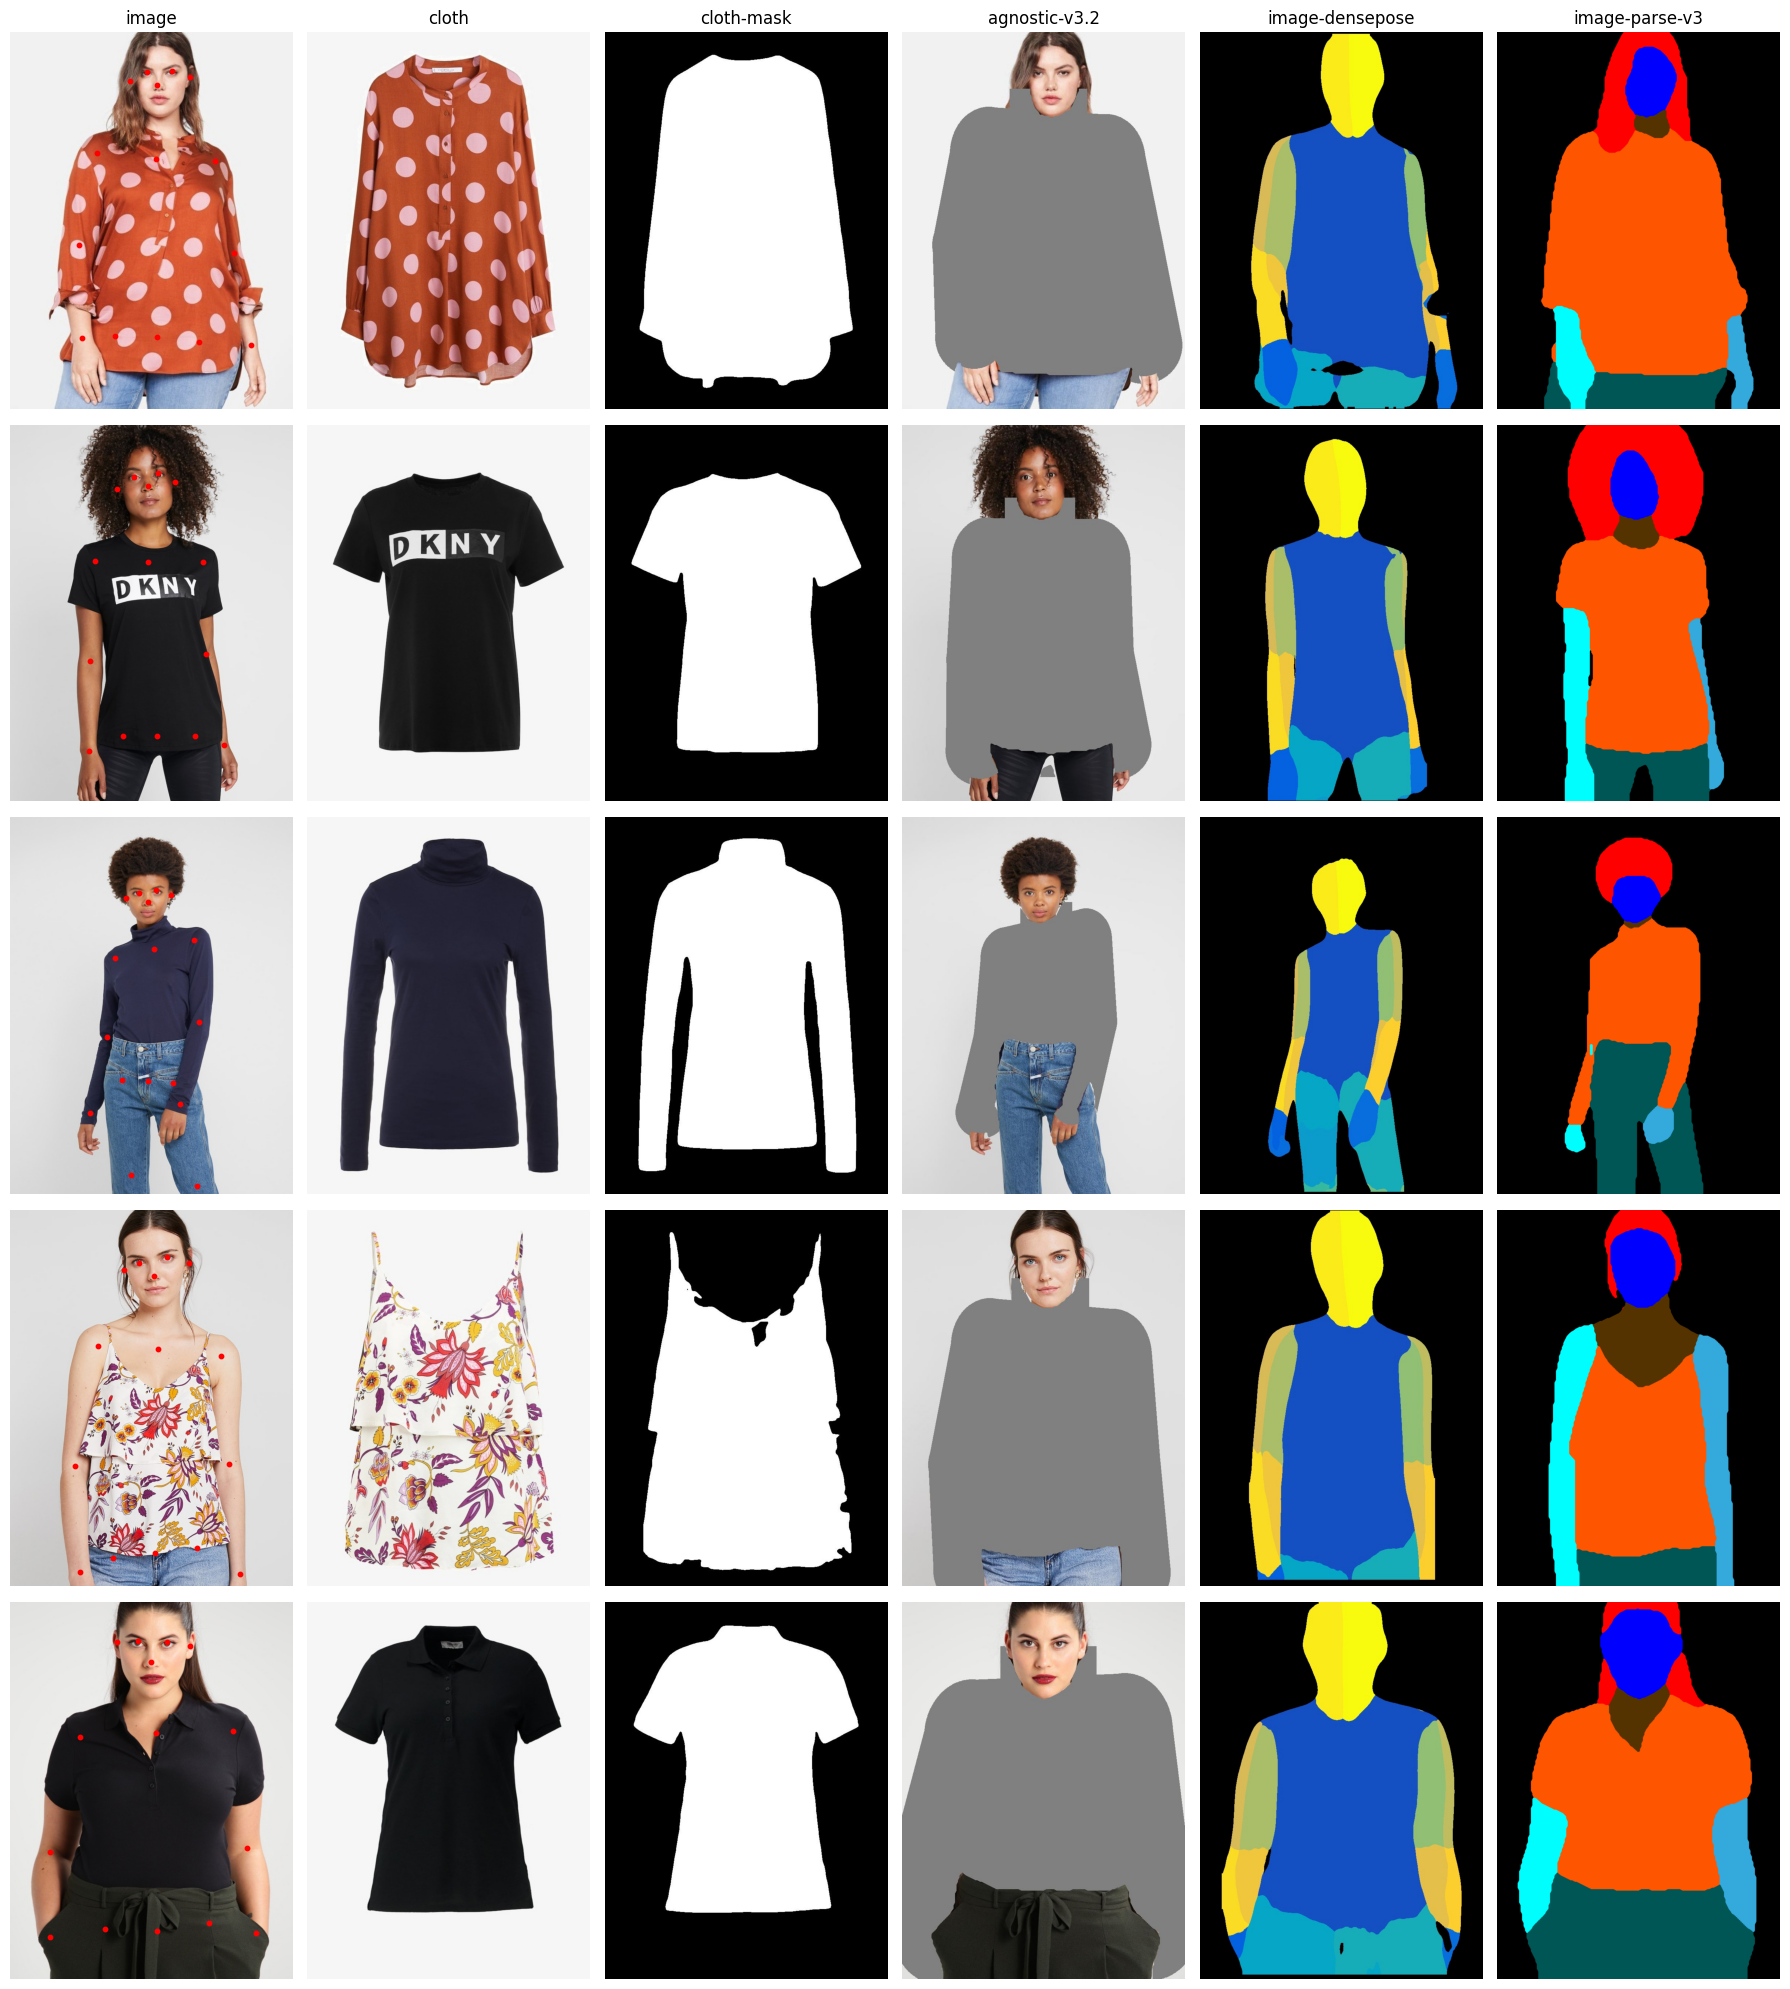

In [6]:
# Show a few samples with every input side by side, and the pose keypoints on the photo
columns = ["image", "cloth", "cloth-mask", "agnostic-v3.2", "image-densepose", "image-parse-v3"]
fig, axes = plt.subplots(5, len(columns), figsize=(18, 20))

for row, sample_id in enumerate(train_sub[:5]):
    for col, folder in enumerate(columns):
        picture = Image.open(train_files[folder][sample_id])
        if folder in PARSE_FOLDERS:
            picture = picture.convert("RGB")   # show the label colours
        axes[row, col].imshow(picture, cmap="gray")
        axes[row, col].axis("off")
        axes[0, col].set_title(folder)

    pose = load_pose(train_files["openpose_json"][sample_id])
    visible = pose[:, 2] > 0
    axes[row, 0].scatter(pose[visible, 0], pose[visible, 1], s=10, c="red")

plt.tight_layout()
plt.show()

In [7]:
# Check what's inside a parsing map: one label number per pixel, so it must never be blended
parse = Image.open(train_files["image-parse-v3"][train_sub[0]])
print("mode:", parse.mode, "| size:", parse.size, "| labels used:", np.unique(np.array(parse)))

mode: P | size: (768, 1024) | labels used: [ 0  2  5  9 10 13 14 15]


  0%|          | 0/1000 [00:00<?, ?it/s]

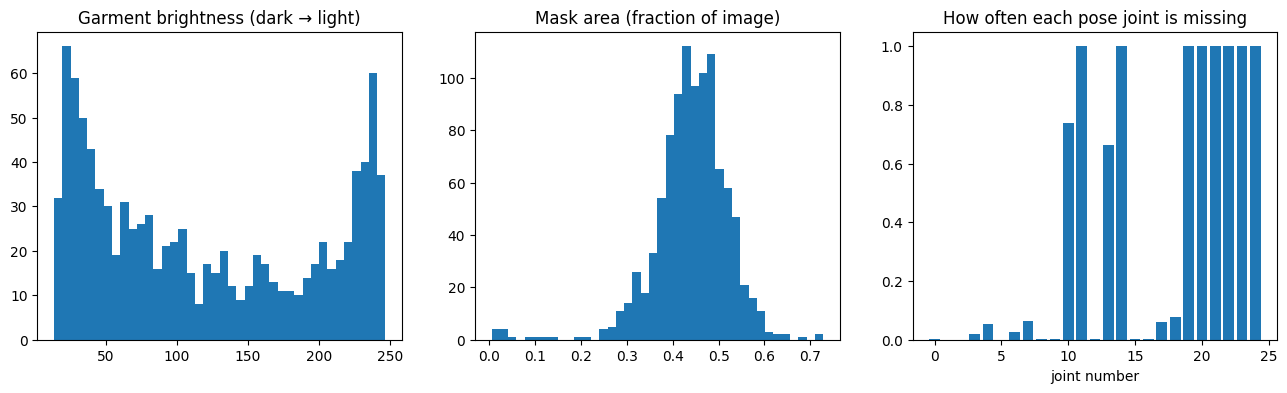

In [8]:
# Look at garment brightness, mask size and missing pose joints
eda_ids = train_sub[:1000]
brightness, mask_area, joint_missing = [], [], []

for sample_id in tqdm(eda_ids):
    cloth = np.array(Image.open(train_files["cloth"][sample_id]).convert("RGB"))
    mask = load_mask(train_files["cloth-mask"][sample_id])
    brightness.append(cloth[mask].mean() if mask.any() else np.nan)
    mask_area.append(mask.mean())
    joint_missing.append(load_pose(train_files["openpose_json"][sample_id])[:, 2] == 0)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(brightness, bins=40)
axes[0].set_title("Garment brightness (dark → light)")
axes[1].hist(mask_area, bins=40)
axes[1].set_title("Mask area (fraction of image)")
axes[2].bar(range(25), np.mean(joint_missing, axis=0))
axes[2].set_title("How often each pose joint is missing")
axes[2].set_xlabel("joint number")
plt.show()

  0%|          | 0/11647 [00:00<?, ?it/s]

145 samples have a broken mask and will be left out


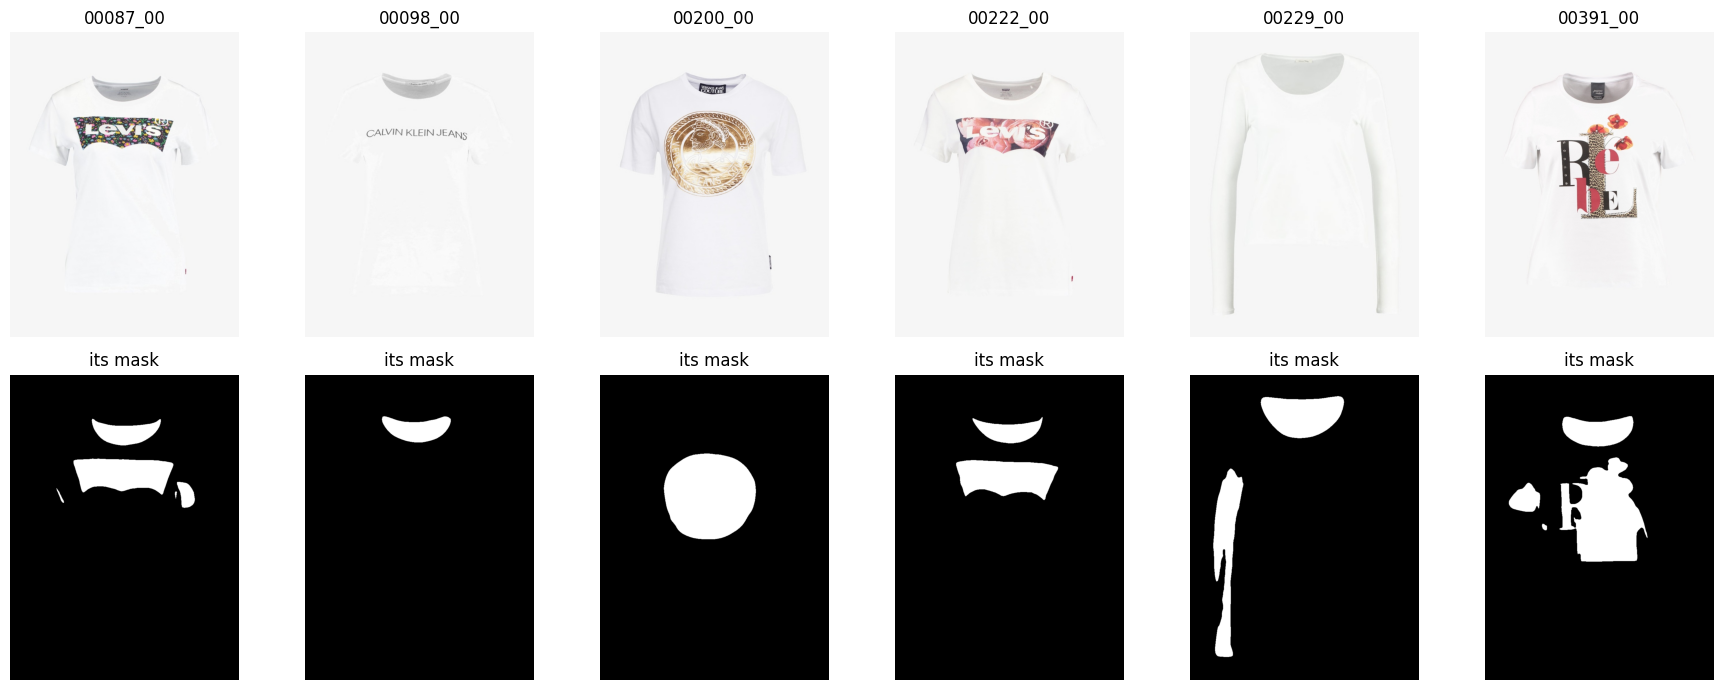

In [9]:
# Find garments whose mask is almost empty (under 15% of the image) and leave them out.
# Most are white tops on a white background, where the original mask failed.
def is_broken(files, sample_id):
    return load_mask(files["cloth-mask"][sample_id]).mean() < 0.15

broken = {i: train_files for i in tqdm(train_sub + val_sub) if is_broken(train_files, i)}
broken.update({i: test_files for i in test_sub if is_broken(test_files, i)})
bad_ids = set(broken)
print(f"{len(bad_ids)} samples have a broken mask and will be left out")

examples = sorted(bad_ids)[:6]
fig, axes = plt.subplots(2, len(examples), figsize=(3 * len(examples), 7), squeeze=False)
for col, sample_id in enumerate(examples):
    files = broken[sample_id]
    axes[0, col].imshow(Image.open(files["cloth"][sample_id])); axes[0, col].set_title(sample_id)
    axes[1, col].imshow(load_mask(files["cloth-mask"][sample_id]), cmap="gray"); axes[1, col].set_title("its mask")
    for ax in axes[:, col]:
        ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
# Resize everything to 256x192, clean the masks, keep the upper-body pose
def clean_mask(mask): #Fill small holes and remove small specks; leave big gaps, like under sleeves, alone
    total = mask.size

    holes, n_holes = ndi.label(ndi.binary_fill_holes(mask) & ~mask)
    if n_holes:
        hole_sizes = ndi.sum(np.ones_like(mask), holes, range(1, n_holes + 1))
        small_holes = [k + 1 for k, size in enumerate(hole_sizes) if size < 0.005 * total]
        mask = mask | np.isin(holes, small_holes)

    blobs, n_blobs = ndi.label(mask)
    if n_blobs > 1:
        blob_sizes = ndi.sum(mask, blobs, range(1, n_blobs + 1))
        real_blobs = [k + 1 for k, size in enumerate(blob_sizes) if size >= 0.002 * total]
        mask = np.isin(blobs, real_blobs)

    return mask


def preprocess(ids, files, split):
    out_dir = os.path.join(OUT, split)
    for folder in FOLDERS:
        os.makedirs(os.path.join(out_dir, folder), exist_ok=True)

    def out_path(folder, sample_id, ext):
        return os.path.join(out_dir, folder, f"{sample_id}.{ext}")

    kept, cleaned = [], []
    for sample_id in tqdm(ids, desc=split):
        if sample_id in bad_ids:
            continue


        for folder in ["image", "cloth", "agnostic-v3.2"]: # photos: smooth resize
            photo = Image.open(files[folder][sample_id]).convert("RGB").resize((W, H), Image.BILINEAR)
            photo.save(out_path(folder, sample_id, "jpg"), quality=95)

        #DensePose colours are body-part labels
        densepose = Image.open(files["image-densepose"][sample_id]).convert("RGB").resize((W, H), Image.NEAREST)
        densepose.save(out_path("image-densepose", sample_id, "png"))

        # parsing maps: keep the label numbers as they are and resize
        for folder in PARSE_FOLDERS:
            parse = Image.open(files[folder][sample_id])
            assert parse.mode in ("P", "L"), f"{folder}/{sample_id}: unexpected mode {parse.mode}"
            parse.resize((W, H), Image.NEAREST).save(out_path(folder, sample_id, "png"))

        # mask: resize then clean
        raw_mask = load_mask(files["cloth-mask"][sample_id], size=(W, H))
        mask = clean_mask(raw_mask)
        if (mask != raw_mask).any():
            cleaned.append((sample_id, (mask != raw_mask).mean()))
        Image.fromarray(mask.astype(np.uint8) * 255).save(out_path("cloth-mask", sample_id, "png"))

        # pose: upper body only, coordinates scaled to the new size
        pose = load_pose(files["openpose_json"][sample_id])[UPPER_JOINTS]
        pose[:, 0] *= W / ORIGINAL_W
        pose[:, 1] *= H / ORIGINAL_H
        with open(out_path("openpose_json", sample_id, "json"), "w") as f:
            json.dump(pose.tolist(), f)

        kept.append(sample_id)

    print(f"{split}: kept {len(kept)} samples, cleaned {len(cleaned)} masks")
    return kept, cleaned

train_kept, train_cleaned = preprocess(train_sub, train_files, "train")
val_kept,   val_cleaned   = preprocess(val_sub,   train_files, "val")
test_kept,  test_cleaned  = preprocess(test_sub,  test_files,  "test")

train:   0%|          | 0/10483 [00:00<?, ?it/s]

train: kept 10360 samples, cleaned 1353 masks


val:   0%|          | 0/1164 [00:00<?, ?it/s]

val: kept 1150 samples, cleaned 137 masks


test:   0%|          | 0/2032 [00:00<?, ?it/s]

test: kept 2024 samples, cleaned 258 masks


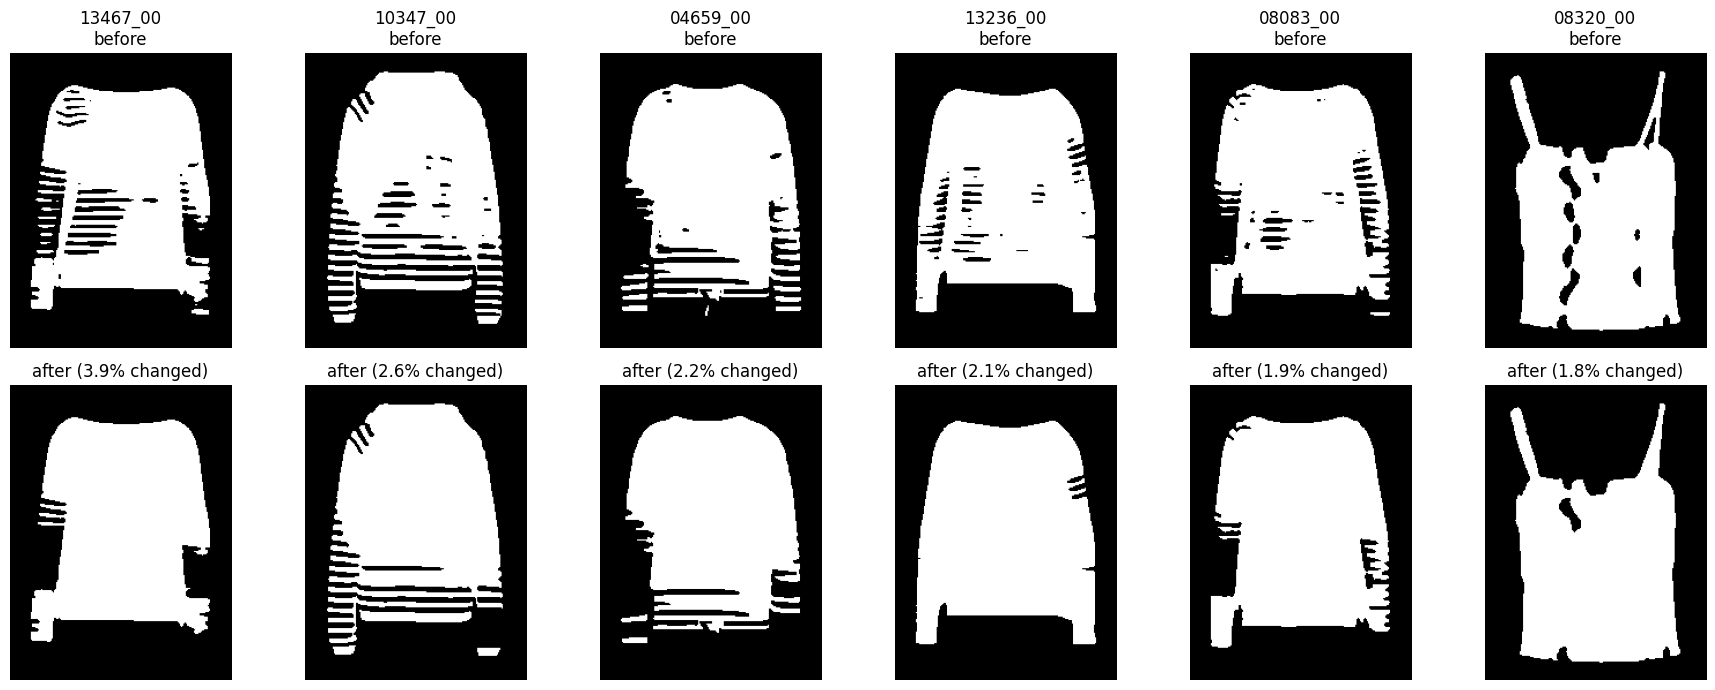

In [11]:
# Compare masks before and after cleaning
most_changed = sorted(train_cleaned, key=lambda item: -item[1])[:6]

fig, axes = plt.subplots(2, len(most_changed), figsize=(3 * len(most_changed), 7), squeeze=False)
for col, (sample_id, changed) in enumerate(most_changed):
    before = load_mask(train_files["cloth-mask"][sample_id], size=(W, H))
    after = load_mask(os.path.join(OUT, "train", "cloth-mask", f"{sample_id}.png"))
    axes[0, col].imshow(before, cmap="gray"); axes[0, col].set_title(f"{sample_id}\nbefore")
    axes[1, col].imshow(after, cmap="gray");  axes[1, col].set_title(f"after ({changed:.1%} changed)")
    for ax in axes[:, col]:
        ax.axis("off")
plt.tight_layout()
plt.show()

In [12]:
!pip -q install imagehash

In [13]:
# Find validation/test garments that are the same garment as one in train, since they'd leak into evaluation.
# Two garments count as the same only if BOTH the shape and the colours/print match.
import imagehash

def garment_fingerprints(split, ids):
    """Shape fingerprint: 64 bits that are nearly identical for photos of the same garment."""
    return {i: imagehash.phash(Image.open(os.path.join(OUT, split, "cloth", f"{i}.jpg"))).hash.flatten()
            for i in tqdm(ids, desc=split)}

def thumbnail(split, sample_id):
    """Tiny 24x32 colour version of the garment photo, to compare colours and print."""
    photo = Image.open(os.path.join(OUT, split, "cloth", f"{sample_id}.jpg")).resize((24, 32))
    return np.array(photo, dtype=np.float32)

train_prints = garment_fingerprints("train", train_kept)
train_names = list(train_prints)
train_bits = np.array(list(train_prints.values()))

duplicates = []   # (split, sample id, matching train id)
for split, kept in [("val", val_kept), ("test", test_kept)]:
    for sample_id, bits in garment_fingerprints(split, kept).items():
        distance = (train_bits != bits).sum(axis=1)       # how many of the 64 bits differ
        for j in np.where(distance <= 2)[0]:              # same shape...
            colour_gap = np.abs(thumbnail(split, sample_id) - thumbnail("train", train_names[j])).mean()
            if colour_gap < 5:                            # ...and same colours and print
                duplicates.append((split, sample_id, train_names[j]))
                break

for split in ["val", "test"]:
    print(f"{split}: {sum(d[0] == split for d in duplicates)} garments also appear in train")

train:   0%|          | 0/10360 [00:00<?, ?it/s]

val:   0%|          | 0/1150 [00:00<?, ?it/s]

test:   0%|          | 0/2024 [00:00<?, ?it/s]

val: 16 garments also appear in train
test: 35 garments also appear in train


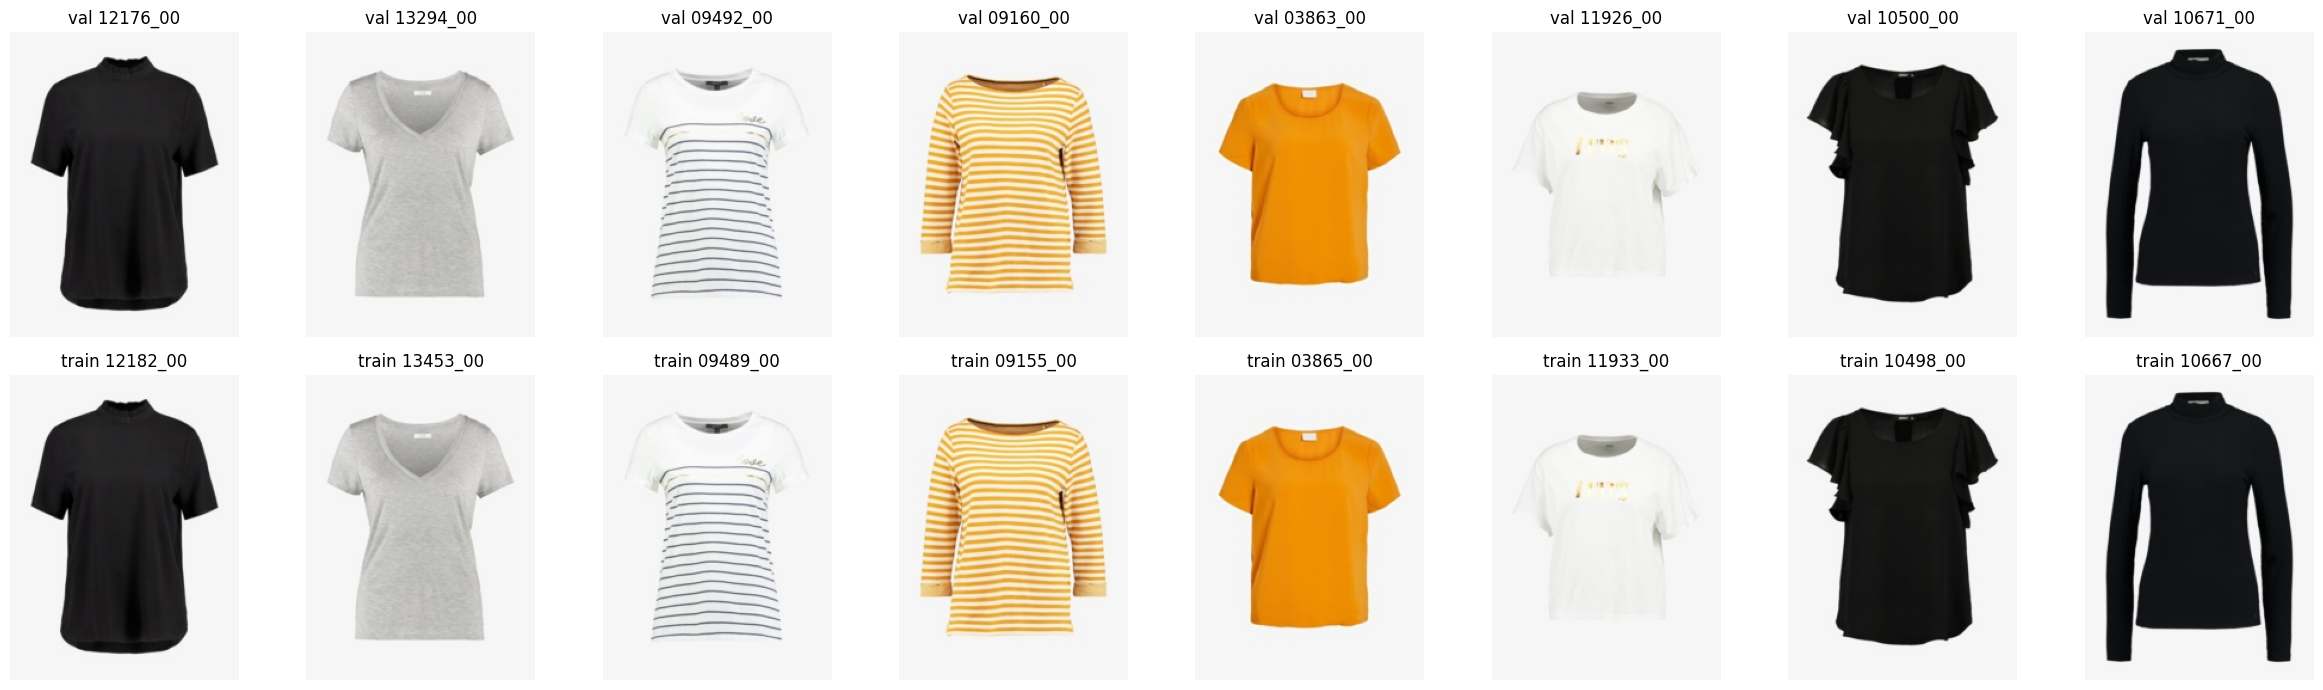

In [14]:
# Show some of the pairs to confirm they really are the same garment
shown = duplicates[:8]
if shown:
    fig, axes = plt.subplots(2, len(shown), figsize=(3 * len(shown), 7), squeeze=False)
    for col, (split, sample_id, train_id) in enumerate(shown):
        axes[0, col].imshow(Image.open(os.path.join(OUT, split, "cloth", f"{sample_id}.jpg")))
        axes[0, col].set_title(f"{split} {sample_id}")
        axes[1, col].imshow(Image.open(os.path.join(OUT, "train", "cloth", f"{train_id}.jpg")))
        axes[1, col].set_title(f"train {train_id}")
        for ax in axes[:, col]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

In [15]:
# make sure to remove those samples from validation/test
leaked = {(split, sample_id) for split, sample_id, _ in duplicates}
for split, sample_id in leaked:
    for file in glob.glob(os.path.join(OUT, split, "*", f"{sample_id}.*")):
        os.remove(file)

val_kept = [i for i in val_kept if ("val", i) not in leaked]
test_kept = [i for i in test_kept if ("test", i) not in leaked]
print(f"Removed {len(leaked)} samples | left: {len(val_kept)} validation, {len(test_kept)} test")

Removed 51 samples | left: 1134 validation, 1989 test


In [16]:
#pyTorch dataset, loads saved sample as tensors ready for the model
class TryOnDataset(Dataset):
    def __init__(self, split, paired=True, seed=0):
        self.dir = os.path.join(OUT, split)
        self.person_ids = sorted(f[:-4] for f in os.listdir(os.path.join(self.dir, "image")))

        if paired:
            self.cloth_ids = self.person_ids
        else:
            # shuffle, then give the next person's garment
            shuffled = self.person_ids[:]
            random.Random(seed).shuffle(shuffled)
            next_garment = dict(zip(shuffled, shuffled[1:] + shuffled[:1]))
            self.cloth_ids = [next_garment[p] for p in self.person_ids]

        self.ys, self.xs = np.mgrid[0:H, 0:W]

    def __len__(self):
        return len(self.person_ids)

    def load_image(self, folder, sample_id, ext):
        pixels = np.array(Image.open(os.path.join(self.dir, folder, f"{sample_id}.{ext}")).convert("RGB"))
        return torch.from_numpy(pixels / 127.5 - 1).float().permute(2, 0, 1)

    def load_labels(self, folder, sample_id):
        labels = np.array(Image.open(os.path.join(self.dir, folder, f"{sample_id}.png")))
        return torch.from_numpy(labels).long()

    def pose_heatmaps(self, pose, sigma=3):
        maps = np.zeros((len(pose), H, W), dtype=np.float32)
        for j, (x, y, confidence) in enumerate(pose):
            if confidence > 0:
                maps[j] = np.exp(-((self.xs - x) ** 2 + (self.ys - y) ** 2) / (2 * sigma ** 2))
        return torch.from_numpy(maps)

    def __getitem__(self, idx):
        person, cloth = self.person_ids[idx], self.cloth_ids[idx]

        with open(os.path.join(self.dir, "openpose_json", f"{person}.json")) as f:
            pose = np.array(json.load(f), dtype=np.float32)
        mask = load_mask(os.path.join(self.dir, "cloth-mask", f"{cloth}.png"))

        return {
            "agnostic":       self.load_image("agnostic-v3.2", person, "jpg"),
            "densepose":      self.load_image("image-densepose", person, "png"),
            "parse":          self.load_labels("image-parse-v3", person),
            "parse_agnostic": self.load_labels("image-parse-agnostic-v3.2", person),
            "pose":           torch.from_numpy(pose),
            "pose_map":       self.pose_heatmaps(pose),
            "cloth":          self.load_image("cloth", cloth, "jpg"),
            "cloth_mask":     torch.from_numpy(mask).float()[None],
            "person":         self.load_image("image", person, "jpg"),
        }


train_set     = TryOnDataset("train")
val_set       = TryOnDataset("val")
test_paired   = TryOnDataset("test", paired=True)
test_unpaired = TryOnDataset("test", paired=False)

print(f"train: {len(train_set)}   val: {len(val_set)}   test: {len(test_paired)}")
for key, value in train_set[0].items():
    print(f"  {key:<15} {tuple(value.shape)}")

train: 10360   val: 1134   test: 1989
  agnostic        (3, 256, 192)
  densepose       (3, 256, 192)
  parse           (256, 192)
  parse_agnostic  (256, 192)
  pose            (15, 3)
  pose_map        (15, 256, 192)
  cloth           (3, 256, 192)
  cloth_mask      (1, 256, 192)
  person          (3, 256, 192)


In [17]:
# undo the [-1, 1] scaling so matplotlib can show a tensor as a picture
def to_picture(tensor):
    return ((tensor.permute(1, 2, 0).numpy() + 1) / 2).clip(0, 1)

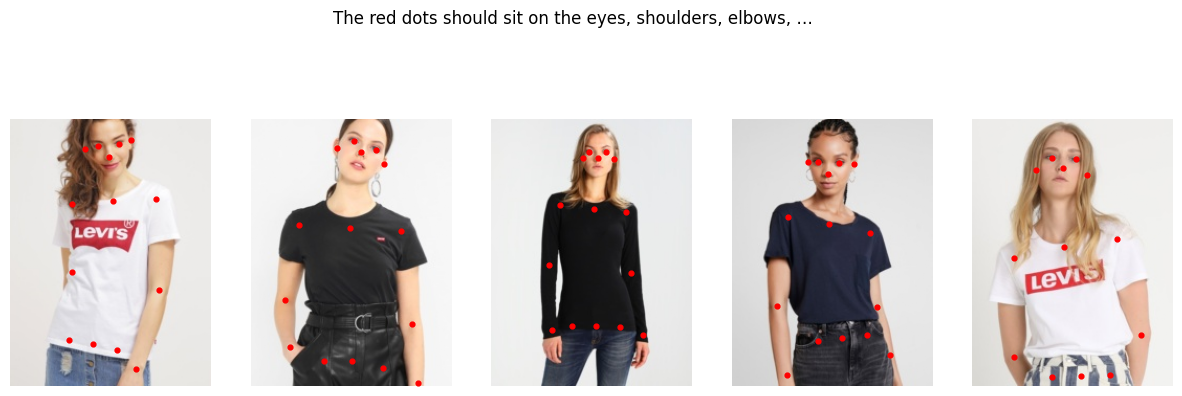

In [18]:
# Check that the scaled pose points still land on the right body parts
fig, axes = plt.subplots(1, 5, figsize=(15, 5))
for ax, idx in zip(axes, range(5)):
    sample = train_set[idx]
    pose = sample["pose"].numpy()
    visible = pose[:, 2] > 0
    ax.imshow(to_picture(sample["person"]))
    ax.scatter(pose[visible, 0], pose[visible, 1], s=12, c="red")
    ax.axis("off")
plt.suptitle("The red dots should sit on the eyes, shoulders, elbows, …")
plt.show()

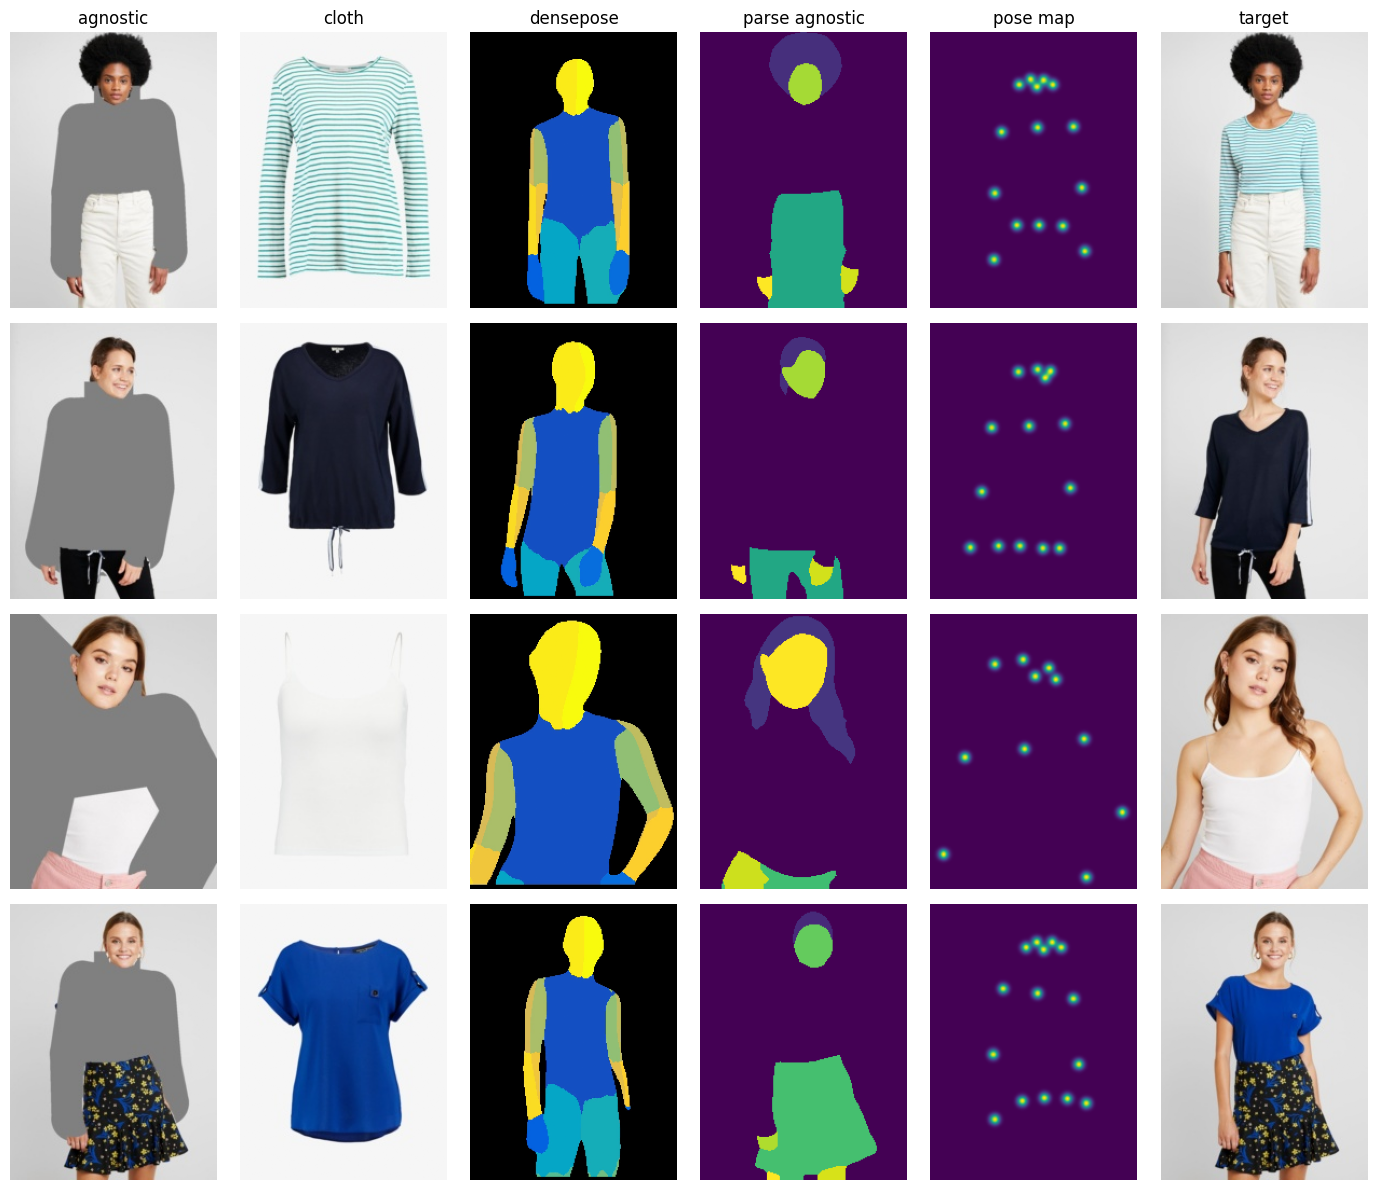

In [19]:
# Load one batch through the DataLoader and show what the model will actually get
loader = DataLoader(train_set, batch_size=8, shuffle=True, num_workers=2)
batch = next(iter(loader))

panels = [
    ("agnostic",       lambda i: to_picture(batch["agnostic"][i])),
    ("cloth",          lambda i: to_picture(batch["cloth"][i])),
    ("densepose",      lambda i: to_picture(batch["densepose"][i])),
    ("parse agnostic", lambda i: batch["parse_agnostic"][i]),
    ("pose map",       lambda i: batch["pose_map"][i].sum(0)),
    ("target",         lambda i: to_picture(batch["person"][i])),
]

fig, axes = plt.subplots(4, len(panels), figsize=(14, 12))
for row in range(4):
    for col, (title, picture) in enumerate(panels):
        axes[row, col].imshow(picture(row))
        axes[row, col].axis("off")
        axes[0, col].set_title(title)
plt.tight_layout()
plt.show()

In [20]:
# Zip the cleaned data (train, val and test) and save it to Google Drive
from google.colab import drive
drive.mount("/content/drive")

!zip -qr /content/drive/MyDrive/{OUT}.zip {OUT}
print(f"Saved {OUT}.zip to Google Drive")

Mounted at /content/drive
Saved vitonhd_256x192.zip to Google Drive
